<a href="https://colab.research.google.com/github/Vinz602/DS-FraudDetection/blob/main/FraudDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
kagglehub.login()

# Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Download latest version
path = kagglehub.competition_download('GiveMeSomeCredit')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/GiveMeSomeCredit


In [ ]:
df_dict = pd.read_excel(path + '/Data Dictionary.xls')
df_dict

,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer


In [ ]:
for col in df_dict['Unnamed: 0']:
    print(col)
print("====================================================================")
for col in df_dict['Unnamed: 1']:
    print(col)

Variable Name
SeriousDlqin2yrs
RevolvingUtilizationOfUnsecuredLines
age
NumberOfTime30-59DaysPastDueNotWorse
DebtRatio
MonthlyIncome
NumberOfOpenCreditLinesAndLoans
NumberOfTimes90DaysLate
NumberRealEstateLoansOrLines
NumberOfTime60-89DaysPastDueNotWorse
NumberOfDependents
Description
Person experienced 90 days past due delinquency or worse 
Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans divided by the sum of credit limits
Age of borrower in years
Number of times borrower has been 30-59 days past due but no worse in the last 2 years.
Monthly debt payments, alimony,living costs divided by monthy gross income
Monthly income
Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards)
Number of times borrower has been 90 days or more past due.
Number of mortgage and real estate loans including home equity lines of credit
Number of times borrower has been 60-89 days past due but no

## Target = SeriousDlqin2yrs (Person experienced 90 days past due delinquency or worse)

---



In [ ]:
TARGET = 'SeriousDlqin2yrs'

In [ ]:
df_train = pd.read_csv(path + '/cs-training.csv')
df_train

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [ ]:
df_test = pd.read_csv(path + '/cs-test.csv')
df_test

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,NaN,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,2,NaN,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,3,NaN,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,4,NaN,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,5,NaN,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
101498,101499,NaN,0.282653,24,0,0.068522,1400.0,5,0,0,0,0.0
101499,101500,NaN,0.922156,36,3,0.934217,7615.0,8,0,2,0,4.0
101500,101501,NaN,0.081596,70,0,836.000000,NaN,3,0,0,0,NaN
101501,101502,NaN,0.335457,56,0,3568.000000,NaN,8,0,2,1,3.0


In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101503 entries, 0 to 101502
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            101503 non-null  int64  
 1   SeriousDlqin2yrs                      0 non-null       float64
 2   RevolvingUtilizationOfUnsecuredLines  101503 non-null  float64
 3   age                                   101503 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  101503 non-null  int64  
 5   DebtRatio                             101503 non-null  float64
 6   MonthlyIncome                         81400 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       101503 non-null  int64  
 8   NumberOfTimes90DaysLate               101503 non-null  int64  
 9   NumberRealEstateLoansOrLines          101503 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  101503 non-null  int64  
 11  

In [ ]:
df_test.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,101503.000000,0.0,101503.000000,101503.000000,101503.000000,101503.000000,8.140000e+04,101503.000000,101503.000000,101503.000000,101503.000000,98877.000000
mean,50752.000000,NaN,5.310000,52.405436,0.453770,344.475020,6.855036e+03,8.453514,0.296691,1.013074,0.270317,0.769046
std,29301.536524,NaN,196.156039,14.779756,4.538487,1632.595231,3.650860e+04,5.144100,4.515859,1.110253,4.503578,1.136778
min,1.000000,NaN,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25376.500000,NaN,0.030131,41.000000,0.000000,0.173423,3.408000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,50752.000000,NaN,0.152586,52.000000,0.000000,0.364260,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,76127.500000,NaN,0.564225,63.000000,0.000000,0.851619,8.200000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,101503.000000,NaN,21821.000000,104.000000,98.000000,268326.000000,7.727000e+06,85.000000,98.000000,37.000000,98.000000,43.000000


In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [ ]:
df_train.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [ ]:
#Pada NumberOfTimes90DaysLate, NumberOfTime30-59DaysPastDueNotWorse, NumberOfTimes90DaysLate max nya
# adalah 98 dimana itu tidak mungkin jadi akan dihapus

In [ ]:
df_train.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


# Data Preprocess

In [ ]:
df_train.drop(columns=['Unnamed: 0'], inplace=True)
df_test.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
#NumberOfDependents -> Number of dependents in family excluding themselves (spouse, children etc.)
#Karena ada beberapa yang null, akan saya anggap mereka tidak punya dependent (0)

df_train['NumberOfDependents'] = df_train['NumberOfDependents'].fillna(0)

# Untuk MonthlyIncome, karena fitur itu penting, jadi ga bisa di drop.

In [ ]:
df_train.drop_duplicates()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149995,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    150000 non-null  float64
dtype

# Exploratory Data


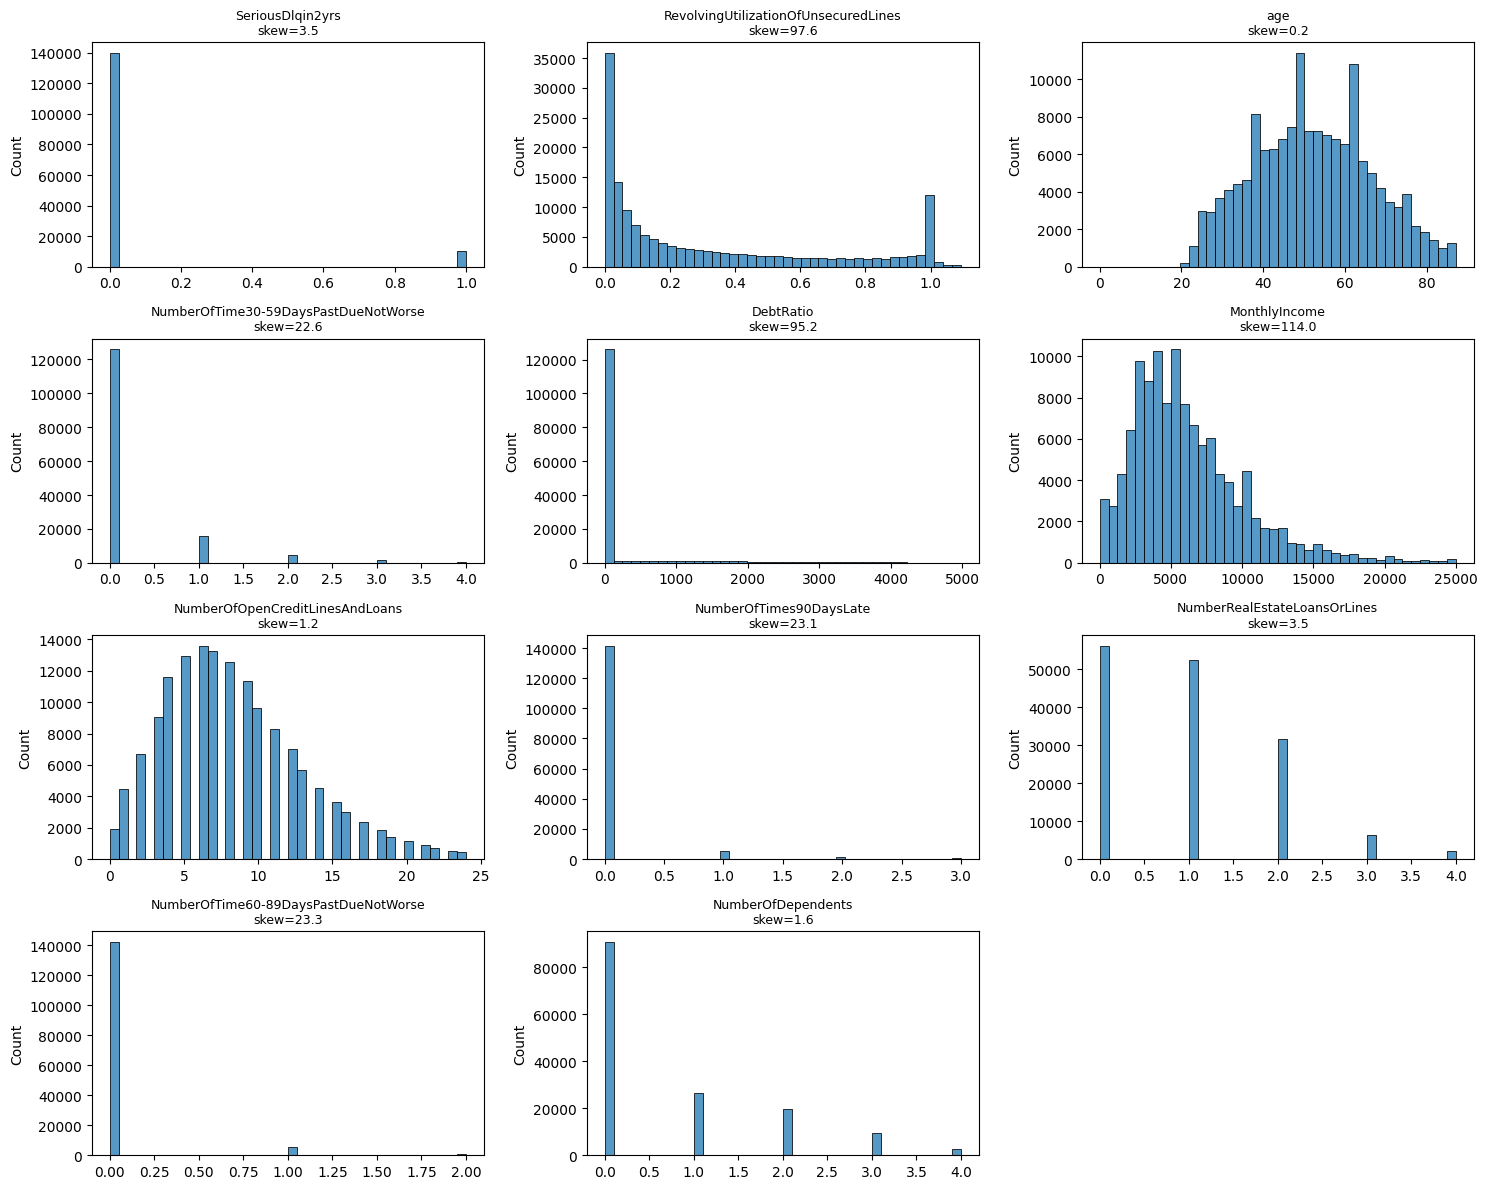

In [ ]:
cols = df_train.columns
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.ravel(), cols):
    # clip to the 99th percentile so the tail doesn't flatten the plot
    s = df_train[c].dropna()
    sns.histplot(s[s <= s.quantile(0.99)], bins=40, ax=ax)
    ax.set_title(f"{c}\nskew={df_train[c].skew():.1f}", fontsize=9)
    ax.set_xlabel("")
for ax in axes.ravel()[len(cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

SeriousDlqin2yrs
0    139974
1     10026

default rate     : 6.684%
imbalance ratio  : 14.0 : 1
baseline accuracy (always predict 0): 93.316%


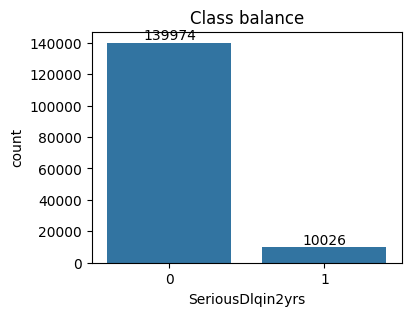

In [ ]:
counts = df_train[TARGET].value_counts()
rate = df_train[TARGET].mean()
print(counts.to_string())
print(f"\ndefault rate     : {rate:.3%}")
print(f"imbalance ratio  : {counts[0]/counts[1]:.1f} : 1")
print(f"baseline accuracy (always predict 0): {1-rate:.3%}")

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(x=TARGET, data=df_train, ax=ax)
for c in ax.containers: ax.bar_label(c)
ax.set_title("Class balance")
plt.show()

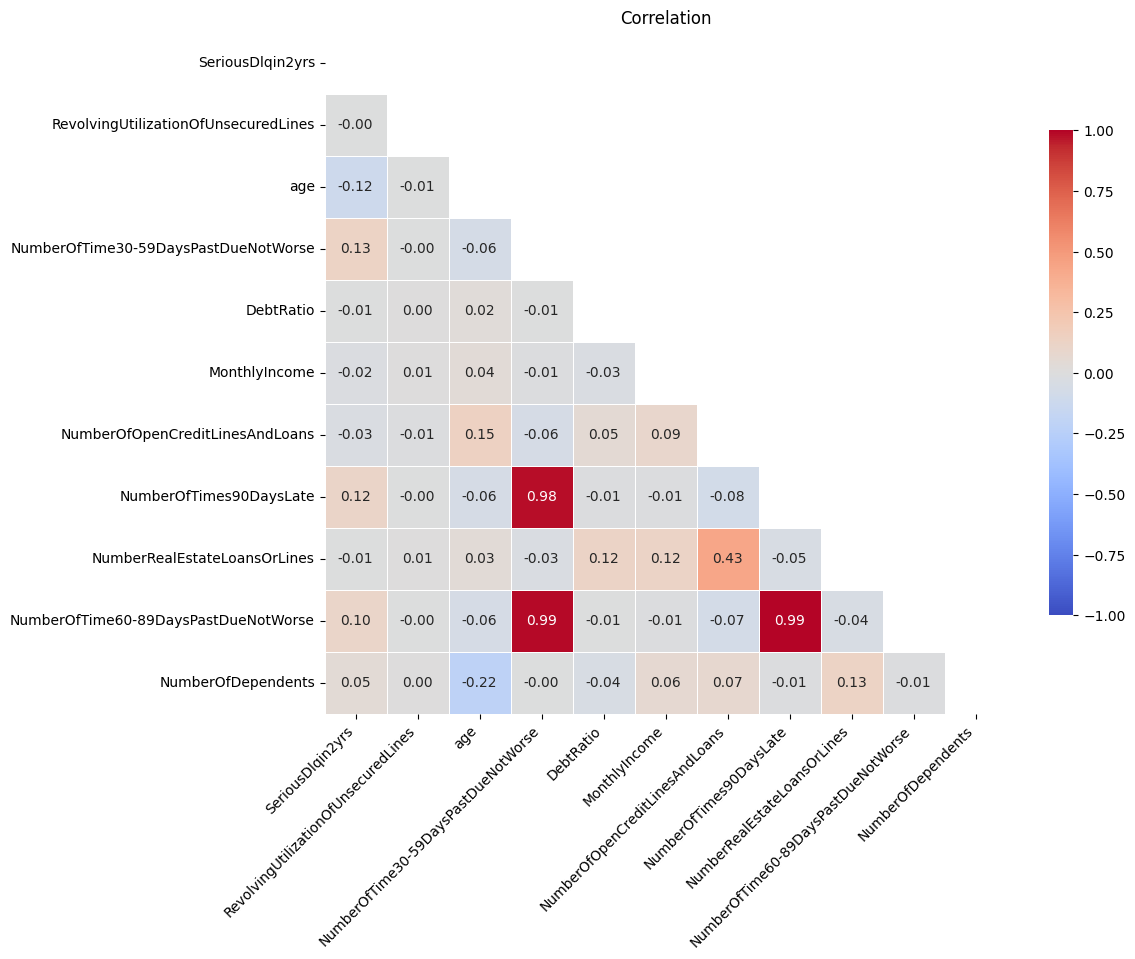

In [ ]:
corr = df_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the redundant half
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, center=0, square=True, linewidths=.5,
                cbar_kws={'shrink': .7})
plt.title("Correlation"); plt.xticks(rotation=45, ha='right'); plt.show()

# Feature Engineering

In [ ]:
LATE = ['NumberOfTime30-59DaysPastDueNotWorse',
        'NumberOfTimes90DaysLate',
        'NumberOfTime60-89DaysPastDueNotWorse']

def make_features(df):
    X = df.drop(columns=[TARGET]).copy()
    for c in LATE:
        X[c] = X[c].replace([96, 98], np.nan)          # hapus value outlier
    X['income_missing'] = X['MonthlyIncome'].isna().astype(int)
    X['age'] = X['age'].where(X['age'] >= 18)           # ada age = 0 jadi pastikan hanya 18+
    X['RevolvingUtilizationOfUnsecuredLines'] = \
        X['RevolvingUtilizationOfUnsecuredLines'].clip(0, 2) # batasin value 0-2 karena value ribuan itu mustahil
    return X

X, y = make_features(df_train), df_train["SeriousDlqin2yrs"]
print(X.shape)

(150000, 11)


In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 1   age                                   149999 non-null  float64
 2   NumberOfTime30-59DaysPastDueNotWorse  149731 non-null  float64
 3   DebtRatio                             150000 non-null  float64
 4   MonthlyIncome                         120269 non-null  float64
 5   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 6   NumberOfTimes90DaysLate               149731 non-null  float64
 7   NumberRealEstateLoansOrLines          150000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  149731 non-null  float64
 9   NumberOfDependents                    150000 non-null  float64
 10  income_missing                        150000 non-null  int64  
dtype

# Data Splitting

In [ ]:
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_tr.shape, X_val.shape)

(120000, 11) (30000, 11)


# Model Training

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# HistGradientBoosting handles NaN natively, no imputation needed
hgb = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=500, max_leaf_nodes=15,
    min_samples_leaf=50, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=30, random_state=42)

for name, m in [('HistGB', hgb)]:
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_val)[:, 1]
    print(f"{name:7s} ROC-AUC={roc_auc_score(y_val, p):.4f}  "
          f"PR-AUC={average_precision_score(y_val, p):.4f}")

HistGB  ROC-AUC=0.8681  PR-AUC=0.4066


# Evaluation

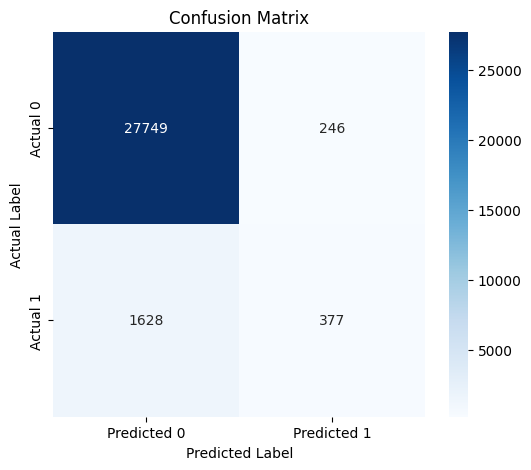

In [ ]:
from sklearn.metrics import confusion_matrix

y_pred = hgb.predict(X_val)

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.99      0.97     27995
           1       0.61      0.19      0.29      2005

    accuracy                           0.94     30000
   macro avg       0.77      0.59      0.63     30000
weighted avg       0.92      0.94      0.92     30000



In [ ]:
X_test = make_features(df_test)

X_test = X_test[X.columns]
assert list(X_test.columns) == list(X.columns)
print(X_test.shape)

hgb.fit(X, y)
test_prob = hgb.predict_proba(X_test)[:, 1]

(101503, 11)


In [ ]:
from pathlib import Path


submission = pd.DataFrame({'Id': df_test.index, 'Probability': test_prob})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,Probability
0,0,0.062222
1,1,0.044249
2,2,0.011418
3,3,0.084251
4,4,0.104645


In [ ]:
assert len(test_prob) == len(sample) == 101503

submission = pd.DataFrame({
    'Id': sample['Id'].values,
    'Probability': test_prob
})
submission.to_csv('submission.csv', index=False)

print(submission.shape)                                   # (101503, 2)
print(submission['Id'].min(), submission['Id'].max())     # 1 101503
print(submission['Id'].is_unique, submission['Probability'].isna().sum())  # True 0

(101503, 2)
1 101503
True 0
